# Sprints AI-Powered Learner Success & Support Agent
## Notebook 01: Practical Data Analytics, Relational Database & EDA (Sprint 1)
**Client:** Sprints (sprints.ai)  
**Track:** AI Pioneers Nationwide Cohort  
**Author:** Mohammed Wael (Lead AI Engineer)

---

### Notebook Overview
This notebook addresses **Sprint 1: Practical Data Analytics**, fulfilling the following client requirements:
1. **Relational Database Design**: SQLite database setup with full schema integrity, primary/foreign keys, indexes, and constraints.
2. **SQL Analytical Extraction**: Executing complex queries to detect progressive grade degradation and aggregate dropout rates across Egyptian governorates.
3. **pandas Data Cleaning & Imputation**: Managing fragmented engagement metrics, handling missing quiz scores with domain-aligned forward-fill and grouped median strategies.
4. **Matplotlib Visual Analytics**: Visualizing drop-out distributions across Egyptian cities, tracking temporal quiz trends, and correlation heatmaps.

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Imported core analytics libraries successfully.")

Imported core analytics libraries successfully.


### 1. Relational Database Initialization & SQL Extraction
We execute `database/setup_and_queries.sql` to initialize our SQLite database (`sprints_learners.db`) and verify table creation.

In [2]:
db_path = os.path.join('..', 'database', 'sprints_learners.db')
sql_path = os.path.join('..', 'database', 'setup_and_queries.sql')

with open(sql_path, 'r', encoding='utf-8') as f:
    sql_script = f.read()

conn = sqlite3.connect(db_path)
cur = conn.cursor()
cur.executescript(sql_script)
conn.commit()

# Inspect tables
cur.execute("SELECT name FROM sqlite_master WHERE type='table';")
print("Tables in sprints_learners.db:", [row[0] for row in cur.fetchall()])

Tables in sprints_learners.db: ['sqlite_sequence', 'cohorts', 'learners', 'course_modules', 'quiz_grades', 'support_tickets', 'interaction_logs']


#### Query 2: Early Risk Detection via Progressive Grade Degradation
Extracting learners exhibiting a score drop $\ge 15$ points from Week 1 to subsequent weeks.

In [3]:
q_degradation = '''
WITH week1_scores AS (
    SELECT learner_id, score AS w1_score
    FROM quiz_grades
    WHERE week_number = 1
),
subsequent_scores AS (
    SELECT learner_id, week_number, score AS current_score
    FROM quiz_grades
    WHERE week_number > 1
)
SELECT 
    l.learner_id,
    l.full_name,
    l.cohort_city,
    w1.w1_score,
    s.week_number AS degraded_at_week,
    s.current_score,
    (w1.w1_score - s.current_score) AS score_drop
FROM learners l
JOIN week1_scores w1 ON l.learner_id = w1.learner_id
JOIN subsequent_scores s ON l.learner_id = s.learner_id
WHERE (w1.w1_score - s.current_score) >= 15.0
ORDER BY score_drop DESC;
'''
df_degrad = pd.read_sql_query(q_degradation, conn)
df_degrad

,learner_id,full_name,cohort_city,w1_score,degraded_at_week,current_score,score_drop
0,LRN-1001,Ahmed Youssef,Cairo,85.0,5,60.0,25.0
1,LRN-1005,Kareem Adel,Assiut,60.0,5,35.0,25.0
2,LRN-1005,Kareem Adel,Assiut,60.0,4,40.0,20.0
3,LRN-1001,Ahmed Youssef,Cairo,85.0,4,70.0,15.0
4,LRN-1005,Kareem Adel,Assiut,60.0,3,45.0,15.0


#### Query 3: Regional Performance & Drop-Out Distribution by Governorate
Aggregating drop-out percentages, quiz performance, and support ticket escalations across Egyptian cities.

In [4]:
q_gov = '''
WITH learner_stats AS (
    SELECT 
        l.cohort_city,
        COUNT(DISTINCT l.learner_id) AS total_learners,
        COUNT(DISTINCT CASE WHEN l.dropped_out = 1 THEN l.learner_id END) AS dropped_out_learners,
        COUNT(DISTINCT t.ticket_id) AS total_support_tickets,
        COUNT(DISTINCT CASE WHEN t.escalation_flag = 1 THEN t.ticket_id END) AS escalated_tickets
    FROM learners l
    LEFT JOIN support_tickets t ON l.learner_id = t.learner_id
    GROUP BY l.cohort_city
),
grade_stats AS (
    SELECT 
        l.cohort_city,
        ROUND(AVG(q.score), 2) AS avg_quiz_score
    FROM learners l
    JOIN quiz_grades q ON l.learner_id = q.learner_id
    GROUP BY l.cohort_city
)
SELECT 
    ls.cohort_city,
    ls.total_learners,
    ls.dropped_out_learners,
    ROUND(CAST(ls.dropped_out_learners AS REAL) * 100.0 / ls.total_learners, 2) AS dropout_rate_pct,
    COALESCE(gs.avg_quiz_score, 0.0) AS avg_quiz_score,
    ls.total_support_tickets,
    ls.escalated_tickets
FROM learner_stats ls
LEFT JOIN grade_stats gs ON ls.cohort_city = gs.cohort_city
ORDER BY dropout_rate_pct DESC, ls.total_learners DESC;
'''
df_gov = pd.read_sql_query(q_gov, conn)
df_gov

,cohort_city,total_learners,dropped_out_learners,dropout_rate_pct,avg_quiz_score,total_support_tickets,escalated_tickets
0,Assiut,1,1,100.0,47.00,1,1
1,Giza,1,1,100.0,35.00,1,1
2,Ismailia,1,1,100.0,20.00,1,1
3,Alexandria,2,1,50.0,96.00,1,0
4,Cairo,3,0,0.0,80.22,2,0
5,Mansoura,1,0,0.0,80.80,1,0
6,Tanta,1,0,0.0,0.00,0,0


### 2. pandas Data Cleaning & Imputation Pipeline
Next, we load the synthetic cohort dataset (`sprints_learner_data.csv`, 2,000 learners) and execute domain-aligned imputation for missing engagement and quiz scores.

In [5]:
csv_path = os.path.join('..', 'data', 'sprints_learner_data.csv')
df = pd.read_csv(csv_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing Values Summary:")
print(df.isna().sum())

Dataset Shape: 2000 rows, 10 columns

Missing Values Summary:
learner_id               0
cohort_city              0
week_1_quiz             15
week_2_quiz            109
week_3_quiz            147
week_4_quiz            262
week_5_quiz            366
project_score          361
forum_feedback_text      0
dropped_out              0
dtype: int64


In [6]:
# Imputation Strategy
quiz_cols = ['week_1_quiz', 'week_2_quiz', 'week_3_quiz', 'week_4_quiz', 'week_5_quiz']
for c in quiz_cols + ['project_score']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# 1. Feature Engineering: Missed Quizzes Count
df['missing_quiz_count'] = df[quiz_cols].isna().sum(axis=1)

# 2. Imputation: Grouped City Median followed by Temporal Forward Fill (carrying forward student mastery)
city_medians = df.groupby('cohort_city')[quiz_cols].transform('median')
df[quiz_cols] = df[quiz_cols].fillna(city_medians)
df[quiz_cols] = df[quiz_cols].ffill(axis=1).bfill(axis=1).fillna(50.0)

# Project score imputation
proj_medians = df.groupby('dropped_out')['project_score'].transform('median')
df['project_score'] = df['project_score'].fillna(proj_medians).fillna(60.0)

print("Imputation Complete. Remaining NaNs in quiz metrics:", df[quiz_cols].isna().sum().sum())

Imputation Complete. Remaining NaNs in quiz metrics: 0


### 3. Matplotlib Visual Analytics: Drop-Out Trends Across Egypt
Mapping out dropout rates across Egyptian governorates and analyzing trajectory comparisons.

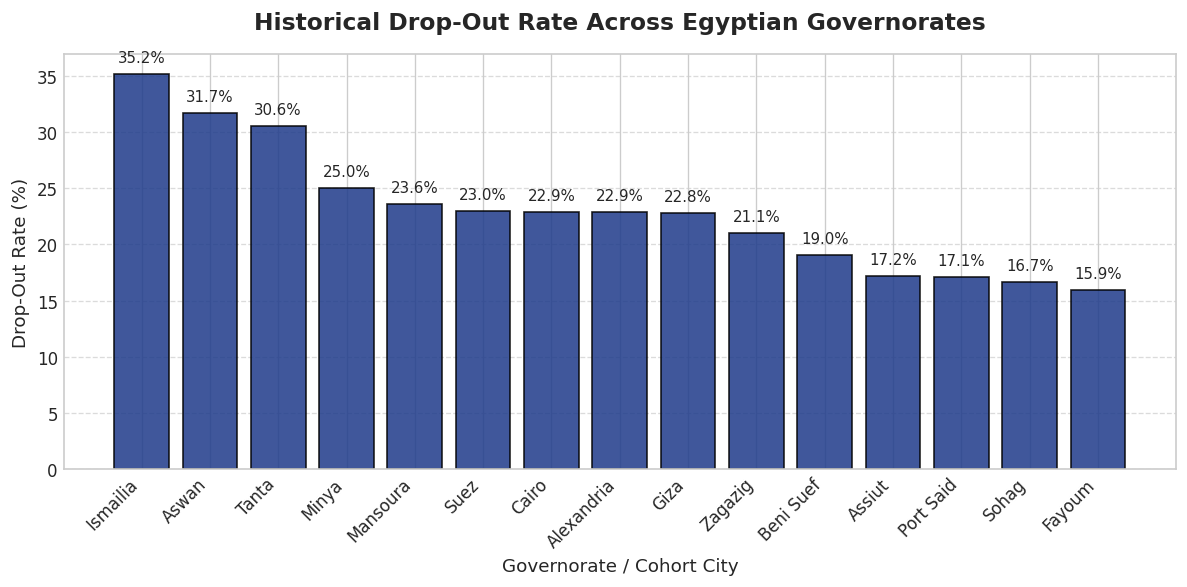

In [7]:
# Group by city for regional dropout analysis
city_summary = df.groupby('cohort_city').agg(
    total=('learner_id', 'count'),
    dropouts=('dropped_out', 'sum'),
    avg_project=('project_score', 'mean')
).reset_index()

city_summary['dropout_pct'] = (city_summary['dropouts'] / city_summary['total']) * 100.0
city_summary = city_summary.sort_values(by='dropout_pct', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(city_summary['cohort_city'], city_summary['dropout_pct'], color='#1e3a8a', edgecolor='black', alpha=0.85)
plt.title('Historical Drop-Out Rate Across Egyptian Governorates', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Governorate / Cohort City', fontsize=11)
plt.ylabel('Drop-Out Rate (%)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight high-risk regions
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

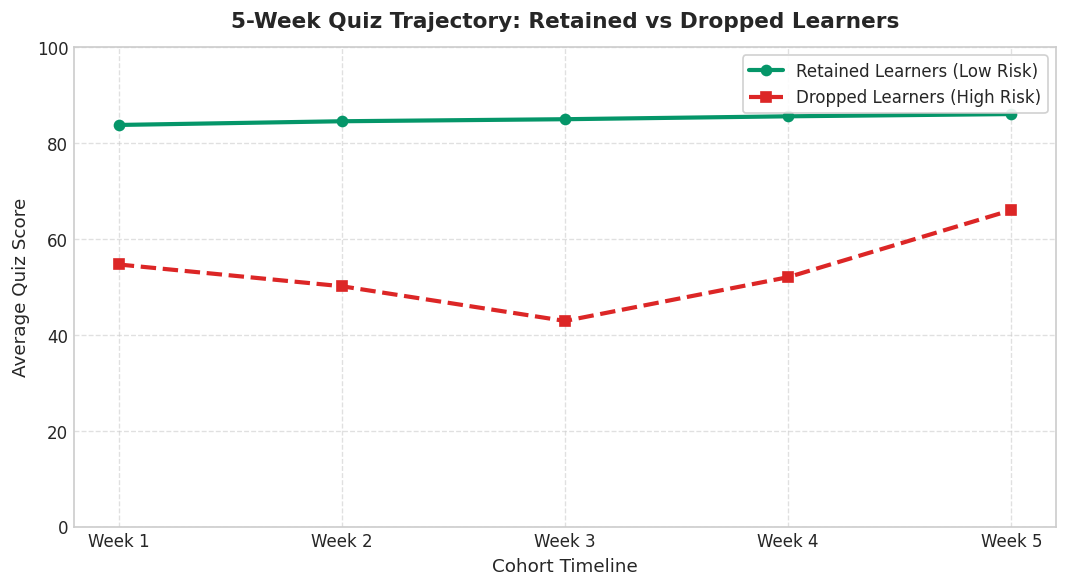

In [8]:
# Weekly Quiz Trajectory: Retained vs Dropped Learners
plt.figure(figsize=(9, 5))
retained_mean = df[df['dropped_out'] == False][quiz_cols].mean()
dropped_mean = df[df['dropped_out'] == True][quiz_cols].mean()

weeks = ['Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5']
plt.plot(weeks, retained_mean, marker='o', linewidth=2.5, color='#059669', label='Retained Learners (Low Risk)')
plt.plot(weeks, dropped_mean, marker='s', linewidth=2.5, color='#dc2626', linestyle='--', label='Dropped Learners (High Risk)')

plt.title('5-Week Quiz Trajectory: Retained vs Dropped Learners', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Cohort Timeline', fontsize=11)
plt.ylabel('Average Quiz Score', fontsize=11)
plt.ylim(0, 100)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 4. Correlation Heatmap of Engagement Features

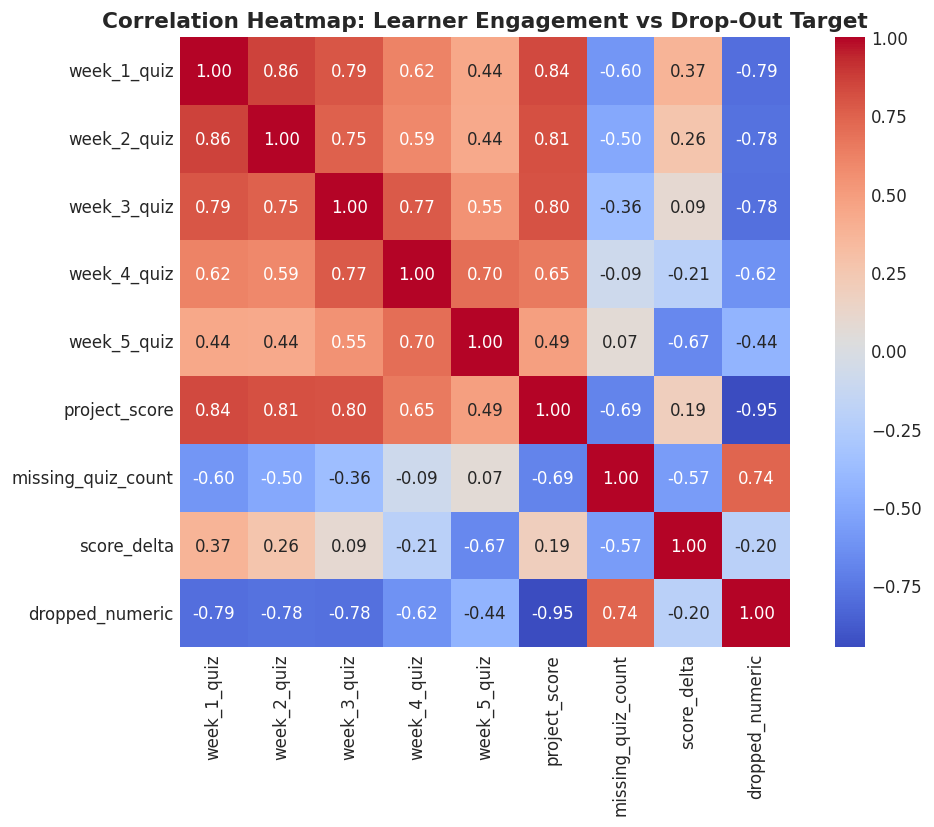

In [9]:
df['score_delta'] = df['week_1_quiz'] - df['week_5_quiz']
df['dropped_numeric'] = df['dropped_out'].astype(int)

corr_features = quiz_cols + ['project_score', 'missing_quiz_count', 'score_delta', 'dropped_numeric']
corr = df[corr_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Heatmap: Learner Engagement vs Drop-Out Target', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()